# Learning

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-17 15:13:23--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-17 15:13:23 (33.2 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [3]:
from pprint import pprint

In [4]:
# read it in to inspect it
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [5]:
len(text)
# no. of characters in dataset

1115394

In [6]:
print(text.split()[:3])
len(text.split()) # approx no. of words

['First', 'Citizen:', 'Before']


202651

In [7]:
text[:3]

'Fir'

In [8]:
chars= sorted(set(text))

In [9]:
len(chars)
# vocab size

65

In [10]:
chars

['\n',
 ' ',
 '!',
 '$',
 '&',
 "'",
 ',',
 '-',
 '.',
 '3',
 ':',
 ';',
 '?',
 'A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y',
 'Z',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [11]:
encoder_dic= {ch:i for i,ch in enumerate(chars)}
encoder_dic

{'\n': 0,
 ' ': 1,
 '!': 2,
 '$': 3,
 '&': 4,
 "'": 5,
 ',': 6,
 '-': 7,
 '.': 8,
 '3': 9,
 ':': 10,
 ';': 11,
 '?': 12,
 'A': 13,
 'B': 14,
 'C': 15,
 'D': 16,
 'E': 17,
 'F': 18,
 'G': 19,
 'H': 20,
 'I': 21,
 'J': 22,
 'K': 23,
 'L': 24,
 'M': 25,
 'N': 26,
 'O': 27,
 'P': 28,
 'Q': 29,
 'R': 30,
 'S': 31,
 'T': 32,
 'U': 33,
 'V': 34,
 'W': 35,
 'X': 36,
 'Y': 37,
 'Z': 38,
 'a': 39,
 'b': 40,
 'c': 41,
 'd': 42,
 'e': 43,
 'f': 44,
 'g': 45,
 'h': 46,
 'i': 47,
 'j': 48,
 'k': 49,
 'l': 50,
 'm': 51,
 'n': 52,
 'o': 53,
 'p': 54,
 'q': 55,
 'r': 56,
 's': 57,
 't': 58,
 'u': 59,
 'v': 60,
 'w': 61,
 'x': 62,
 'y': 63,
 'z': 64}

In [12]:
decoder_dic= {i:ch for i,ch in enumerate(chars)}
decoder_dic

{0: '\n',
 1: ' ',
 2: '!',
 3: '$',
 4: '&',
 5: "'",
 6: ',',
 7: '-',
 8: '.',
 9: '3',
 10: ':',
 11: ';',
 12: '?',
 13: 'A',
 14: 'B',
 15: 'C',
 16: 'D',
 17: 'E',
 18: 'F',
 19: 'G',
 20: 'H',
 21: 'I',
 22: 'J',
 23: 'K',
 24: 'L',
 25: 'M',
 26: 'N',
 27: 'O',
 28: 'P',
 29: 'Q',
 30: 'R',
 31: 'S',
 32: 'T',
 33: 'U',
 34: 'V',
 35: 'W',
 36: 'X',
 37: 'Y',
 38: 'Z',
 39: 'a',
 40: 'b',
 41: 'c',
 42: 'd',
 43: 'e',
 44: 'f',
 45: 'g',
 46: 'h',
 47: 'i',
 48: 'j',
 49: 'k',
 50: 'l',
 51: 'm',
 52: 'n',
 53: 'o',
 54: 'p',
 55: 'q',
 56: 'r',
 57: 's',
 58: 't',
 59: 'u',
 60: 'v',
 61: 'w',
 62: 'x',
 63: 'y',
 64: 'z'}

In [13]:
def encoder_example(text : str)-> list:
  encoded_text= []

  for ch in text:
    encoded_text.append(encoder_dic[ch])

  return encoded_text

print(encoder_example("Aaditya Gangurde"))

[13, 39, 42, 47, 58, 63, 39, 1, 19, 39, 52, 45, 59, 56, 42, 43]


In [14]:
def decoder_example(text : list)-> str:
  decoded_text= ""

  for ch in text:
    decoded_text +=(decoder_dic[ch])

  return (decoded_text)

print(decoder_example(encoder_example("Aaditya Gangurde")))

Aaditya Gangurde


In [15]:
import torch

In [16]:
len(text)

1115394

In [17]:
data= torch.tensor(encoder_example(text))

# we take the entire text, encode it and store it as a tensor
data

tensor([18, 47, 56,  ..., 45,  8,  0])

In [18]:
len(data)

1115394

In [19]:
type(data)

torch.Tensor

In [20]:
training_size= 0.9
train_size= int(training_size*len(data))
train_size

1003854

In [21]:
train_data= data[:train_size]
test_data= data[train_size:]

In [22]:
len(train_data), len(test_data)

(1003854, 111540)

We dont actually train in characters, we send in blocks of tokens instead of passing individual tokens

In [23]:
# this code is just for visualization

block_size= 8
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [24]:
torch.manual_seed(2000) # you can replace 2000 with any no. it doesnt matter

The use of this is that later when we will be using **torch.randint**, it will give the same random no. instead of generating new random no. on every run

In [25]:
batch_size= 4 # process 4 different sections of text parallely
# instead of processing 'A', 'a', 'd', 'i' sequentially, process them simultaneously

context_len= 8 # no. of tokens we feed before prediction
# For predicting 'I' in "METROPOLITAN", we will be feeding "METROPOL"

In [26]:
# We're defining a function that will prepare a batch of training data.

# We don't want to manually select pieces of text every time.

def get_batch(split : str):

  data= train_data if split== 'train' else test_data

  max_start_pos= len(data) - context_len

  start_pos= torch.randint( # generates random no.
      low=0, # lower limit of range
      high=max_start_pos, # higher limit of range
      size=(batch_size,) # no. of random no. generated(here 4)
  )

  print("Starting positions", start_pos)

  input_seq=[]
  # each has block_size(4) length
  # we will start at one of the random indices

  for start in start_pos:
    seq= data[start:start+context_len]
    input_seq.append(seq)

  input_batch= torch.stack(input_seq)
  # stacks resultant seq one after another in form of tensors

  # Build the target sequences: same as the inputs, but shifted
  # one position to the right (i.e. "predict the next token").
  target_seq = []
  for start in start_pos:
      seq = data[start + 1 : start + block_size + 1]
      target_seq.append(seq)
  target_batch = torch.stack(target_seq)

  return input_batch, target_batch


suppose the length of text is 10.  
if the the block size is 3, we can't have all block sizes equal as 10 is not divisible by 3.  
so we make sure that our random starting position leaves enough room for the block size to fit in

In [27]:
type(train_data)

torch.Tensor

In [28]:
# input_batch:  (batch_size, block_size) tensor of input sequences
# target_batch: (batch_size, block_size) tensor of the "next token" targets

input_batch, target_batch= get_batch('train')

Starting positions tensor([968838, 574334, 344436, 682851])


In [29]:
print("input size", input_batch.shape)
# no. of seq = 4
# each seq has size of 8

input size torch.Size([4, 8])


In [30]:
print('target size', target_batch.shape)

target size torch.Size([4, 8])


In [31]:
for batch_index in range(batch_size):
  print(f"\nBatch : {batch_index}")

  for time_step in range(context_len):
    context= input_batch[batch_index, :time_step+1]
    target= target_batch[batch_index, time_step]

    print(f"When input is {context.tolist()} the target: {target.item()}")


Batch : 0
When input is [46] the target: 47
When input is [46, 47] the target: 51
When input is [46, 47, 51] the target: 1
When input is [46, 47, 51, 1] the target: 58
When input is [46, 47, 51, 1, 58] the target: 46
When input is [46, 47, 51, 1, 58, 46] the target: 39
When input is [46, 47, 51, 1, 58, 46, 39] the target: 58
When input is [46, 47, 51, 1, 58, 46, 39, 58] the target: 1

Batch : 1
When input is [1] the target: 44
When input is [1, 44] the target: 56
When input is [1, 44, 56] the target: 53
When input is [1, 44, 56, 53] the target: 51
When input is [1, 44, 56, 53, 51] the target: 1
When input is [1, 44, 56, 53, 51, 1] the target: 58
When input is [1, 44, 56, 53, 51, 1, 58] the target: 46
When input is [1, 44, 56, 53, 51, 1, 58, 46] the target: 43

Batch : 2
When input is [39] the target: 56
When input is [39, 56] the target: 43
When input is [39, 56, 43] the target: 61
When input is [39, 56, 43, 61] the target: 43
When input is [39, 56, 43, 61, 43] the target: 50
When inp

In [32]:
print("Input: ", input_batch)
print("Target: ", target_batch)

Input:  tensor([[46, 47, 51,  1, 58, 46, 39, 58],
        [ 1, 44, 56, 53, 51,  1, 58, 46],
        [39, 56, 43, 61, 43, 50, 50, 57],
        [61, 43,  1, 61, 47, 50, 50,  1]])
Target:  tensor([[47, 51,  1, 58, 46, 39, 58,  1],
        [44, 56, 53, 51,  1, 58, 46, 43],
        [56, 43, 61, 43, 50, 50, 57, 11],
        [43,  1, 61, 47, 50, 50,  1, 54]])


## Bigram Model

A "bigram" language model — the simplest possible language model. It predicts the next character using only the current character (ignores everything before it).  

It's just a lookup table. For every possible character, it stores a row of scores (logits) saying "if you see me, here's how likely every other character is to come next." No attention, no context — just character → next-character probabilities, learned from data.

In [33]:
input_batch.shape

torch.Size([4, 8])

image{/content/ChatGPT Image Sep 29, 2026, 12_36_12 AM.png}

In [34]:
import torch.nn as nn
from torch.nn import functional as F # Provides stateless functional neural networks operation

torch.manual_seed(2000)

class BLM (nn.Module): # BLM= Bigram Language Model

  # Constructor
  def __init__(self, vocab_size): # vocab_size here is 65
    super().__init__() # initializes parent nn Module

    # creating a table of size vocab_size * vocab_size(65)
    # Row i = the raw scores ("logits") for what token comes after token i.
    self.token_embedding_table= nn.Embedding(vocab_size, vocab_size)


  # Calculates loss and logits
  def forward(self, input_batch, target_batch=None): # keeping targets as None by default
    logits=self.token_embedding_table(input_batch)

    if target_batch is None:
      loss=None
    else:

      batch_size, seq_len, vocab_size= logits.shape # (Logits is a 3D matrix)
      # seq_len is just length of context (here 8)

      # tensor.view just reshapes the tensor

      flat_logits= logits.view(batch_size*seq_len, vocab_size)
      # (4,8,65) -> (32,65)

      flat_targets= target_batch.view(batch_size*seq_len)
      # (4,8) -> (32,1)

      loss= F.cross_entropy(flat_logits, flat_targets)

    return logits, loss


  # Generates new tokens at a time and appends to input_batch
  def generate(self, input_batch, max_new_tokens):
    # max_new_tokens is the max no. of new tokens we want to generate
    # input_batch starts as shape (1, 1) — 1 sequence, containing 1 token, which is 0 as start

    # so each iteration generates one new token
    for i in range(max_new_tokens):

    #   # Step 1 - Call forward

    #   model_output= self.forward(input_batch, targets=None)
    #   logits= model_output[0] # (batch_size, seq_len, vocab_size)
    #   loss= model_output[1] # as targets=None, loss will always be None here

    #   # Step 2 - Only keeping Last position prediction
    #   last_position_logits = predicted_logits[:, -1, :]

    #   # Step 3 - Converting raw scores to probability
    #   probs= F.softmax(last_position_logits, dim=-1)

    #   # Step 4 - Randomly sampling one token per sequence
    #   next_token= torch.multinomial(probs, num_samples=1)

    #   # Step 5- Append newly sampled token into input_batch
    #   input_batch= torch.cat((input_batch, next_token), dim=1)


      logits, _ = self(input_batch) # _ is loss that is None
      # shape: (batch_size, seq_len, vocab_size)

      last_step_logits= logits[:,-1, :]
      # shape: (batch_size, vocab_size)
      # Indexing with a single integer (-1) on a dimension removes that dimension entirely

      probs= F.softmax(last_step_logits, dim=-1)
      next_token= torch.multinomial(probs, num_samples=1)
      input_batch= torch.cat((input_batch, next_token), dim=1)

    return input_batch



## Class BLM and Constructor


nn.Module is the base class for PyTorch models.  

```
PyTorch
   │
   └── nn.Module
          │
          ├── Linear
          ├── Embedding
          ├── CNN
          ├── Transformer
          └── YOUR MODEL  
```

```
nn.Module
    ↑
    │ inherits
    │
BigramLanguageModel
```
When you create your model, PyTorch needs to initialize the nn.Module part first.  

super.__init__ basically says that:  
*"Initialize the PyTorch neural-network machinery that I'm inheriting."*


If vocab_size=5, then the Embedding table looks like:
```
                 next-token scores
              0     1     2     3     4
           ┌─────────────────────────────
token 0    │  ?     ?     ?     ?     ?
token 1    │  ?     ?     ?     ?     ?
token 2    │  ?     ?     ?     ?     ?
token 3    │  ?     ?     ?     ?     ?
token 4    │  ?     ?     ?     ?     ?
```

For every position (i,j), the value is a logit that represents the probability or score that token i will be followed by token j.   

**The embedding vector is as large as the vocabulary (here 65).**  



## Forward function

### Step 1:

For every integer in input_tokens, PyTorch looks up that row of the table. So:

Input shape: (4, 8) — just integers
Output shape: (4, 8, 65) — each of the 32 integers (4×8) has been replaced by its own row of 65 numbers.  

> **For every single character in every sequence, we now have a 65-length vector of raw scores**  

### Step 2:  

If no targets were passed in (this happens during generate, where we don't know the "correct" answer — we're creating new text), we skip loss computation entirely and just return the raw logits. The caller will turn these into probabilities and sample from them.  


### Step 3:  

If targets exists, we compute the loss.  

F.cross_entropy expects 2D input: (N, C) ,  
where N = number of predictions,  
C = number of classes.   
But our logits is 3D: (batch, time, vocab).

So we flatten the batch and time dimensions together. (4, 8, 65) becomes (32, 65) — now it's just 32 independent predictions, each a 65-way guess.  

### Step 4:  

We use cross entropy to find loss.  
For each of the 32 predictions:

- Takes the 65 raw scores (flat_logits[i])
- Applies softmax internally to turn them into probabilities
- Looks at the probability assigned to the correct target character (flat_targets[i])
- Computes **-log(probability of correct answer)**, this is high when the model gave the correct answer a low probability, and low (near 0) when the model was confident and correct

Then it averages this across all 32 predictions into a single scalar — that's your loss.  


### Why flatten over looping?  

Flattening the arrays is faster due to vectorized operation and faster on GPU, although using for loop also would be a less viable option

## Generate Function  

Using a sequence of tokens and an extension of n predicted tokens (n<max_new_tokens), we predict the n+1th new token.  

We run the model on current sequence to get predictions for every position. As no targets are provided, *there is no loss*.

We get the predictions for every position.

But, we keep only the prediction for the last/final position, which is the one that is telling what's coming next.  

Then we turn the raw scores into prob distribution (0-1, total sum=1).  

Out of these probabilities, we sample (randomly pick one outcome of probabilities, not necessarily the highest probability). This is done to prevent the model to be too deterministic and repetitive, which would cause prediction of same tokens.  
But the token with higher probability has higher chances of getting picked, but not 100%.  

Then we apply probability distribution on those scores, and predict the next token using torch.multinomial( randomly samples one token with more weightage to those having higher probabilities).   

This new predicted token is then concatenated into the input_batch.  
And the loop keeps running

In [35]:
m= BLM(vocab_size=65) # object of BLM
logits, loss= m(input_batch, target_batch)

In [36]:
pprint(loss)

tensor(4.4291, grad_fn=<NllLossBackward0>)


In [37]:
pprint(logits)

tensor([[[ 1.4071,  1.9527, -1.6511,  ...,  0.5093, -0.2692, -1.4182],
         [-0.8040, -1.4839,  0.3640,  ...,  0.2103,  0.9311,  0.7763],
         [ 0.8410,  0.0580, -0.4502,  ...,  0.3006,  0.1338, -1.2794],
         ...,
         [ 1.4071,  1.9527, -1.6511,  ...,  0.5093, -0.2692, -1.4182],
         [-2.0313, -0.2362, -0.7144,  ..., -1.5406, -1.1535,  1.0117],
         [-1.2118,  0.2181, -0.1878,  ...,  1.3611,  0.9462,  0.2655]],

        [[ 0.1718,  1.1257,  1.0354,  ..., -1.2690,  1.5112,  1.3646],
         [ 0.1515,  2.1250, -0.0929,  ..., -0.9154,  0.6005,  1.1197],
         [ 0.0026, -0.2091,  0.4041,  ..., -0.7074, -1.4831,  0.3110],
         ...,
         [ 0.1718,  1.1257,  1.0354,  ..., -1.2690,  1.5112,  1.3646],
         [-1.2118,  0.2181, -0.1878,  ...,  1.3611,  0.9462,  0.2655],
         [ 1.4071,  1.9527, -1.6511,  ...,  0.5093, -0.2692, -1.4182]],

        [[-2.0313, -0.2362, -0.7144,  ..., -1.5406, -1.1535,  1.0117],
         [ 0.0026, -0.2091,  0.4041,  ..., -0

In [38]:
logits.shape # batch_size, seq_len, vocab_size

torch.Size([4, 8, 65])

In [39]:
decoder_example([0])

'\n'

In [40]:
input_batch

tensor([[46, 47, 51,  1, 58, 46, 39, 58],
        [ 1, 44, 56, 53, 51,  1, 58, 46],
        [39, 56, 43, 61, 43, 50, 50, 57],
        [61, 43,  1, 61, 47, 50, 50,  1]])

In [41]:
print(decoder_example(m.generate(input_batch =torch.zeros((1,1), dtype=torch.long), # starting by a tensor of [0] as input
                         max_new_tokens=100)[0].tolist()))
# Refer the decoder function created at start


IYNy:jFFIGZSGQ:PvO3BKFlQ?'v
.wkzFIuDYTTqzqaQe sytxI;EEwBGh
rpKhv.wLev&gQ U:CweOwsetVelQ-Eze!KDbLMx.M


- m.generate —> run the model's generate method, starting from input_batch and producing 100 new tokens on top of it. Returns a tensor of shape (batch_size, original_len + 100).  

- [0] —> pull out just the first sequence from the batch dimension (since batch_size is likely 1 here). Still a tensor, now shape (original_len + 100,).  

- .tolist() —> convert that tensor into a plain Python list of integers, e.g. [0, 46, 12, ...]. This matters because your decoder function expects a list (per its type hint text: list), and loops over it expecting plain Python ints — not tensor elements — so they match the keys in decoder_dic.  

- decoder(...) —> your function takes that list of integer token IDs, and for each one (ch), looks up the corresponding character in decoder_dic[ch], building up decoded_text one character at a time. Returns the full string.

# Training

In [42]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)
# Adam optimizer

In [43]:
batch_size=64
steps=10000 # no. of training steps (increase later on)

for step in range(steps):

  input_batch, target_batch= get_batch('train')
  # passing 'train' as now we want to train
  # the batches are randomly sampled, so each iteration gives different batches (obv)

  logits, loss= m(input_batch, target_batch)

  optimizer.zero_grad(set_to_none=True)
  loss.backward() # Backpropagation
  optimizer.step() # Update the weights using optimizer

Streaming output truncated to the last 5000 lines.
Starting positions tensor([ 19183, 720552, 124340, 185308, 400312, 361990, 441929, 900240, 963520,
        769284, 879798, 907372, 118083, 627140, 492484,  91138, 992368, 703034,
        614694, 270902, 811482, 989333, 640383, 800319, 861708, 588541, 515911,
         73033, 887595,  68824,  47420,  34131, 101613, 809988, 797373,  55060,
        185709, 266924, 449570,  61437,  32449, 823241, 878270, 677696, 206075,
        510911, 205181, 447764, 740928, 998111, 660174, 221367,  53126, 672500,
        878727, 437800, 394022, 954724, 372085, 942466, 715890, 104914, 193875,
        830574])
Starting positions tensor([577572, 607992, 783436,  98147, 915772, 490057, 867173, 420851, 147209,
          2483, 764896, 118697, 478373, 816659,  46492, 475595, 386014, 242852,
        391154, 630420, 192088, 418330, 622120,  92998, 769969, 392844, 601654,
        371465,  48992, 135095, 353842, 887257, 310798, 383774, 839031, 620660,
        124339

In [44]:
print(loss.item())

# When you compute a loss function (like nn.CrossEntropyLoss),
# PyTorch returns the loss as a 1D tensor,
# that contains the value and tracks its position in the computation graph.
# Using .item() pulls that raw value out

2.5428543090820312


- optimizer.zero_grad() -> Before computing new gradients, **clear out old ones**. PyTorch accumulates gradients by default (adds new ones to existing ones), so without this reset, gradients from previous steps would incorrectly pile up.  set_to_none=True frees the gradient tensors instead of just zeroing their values, which is slightly faster.  

- loss.bckwd() -> Computes the gradient of loss with respect to every trainable parameter in the model.  
These gradients are stored on each parameter (.grad), ready for the optimizer to use.  

- optimizer.step() -> Optimizer updates model parameters, reducting the loss.  

After all the steps finish, print the loss from the very last step only


In [45]:
print(decoder_example(m.generate(input_batch =torch.zeros((1,1), dtype=torch.long), # starting by a tensor of [0] as input
                         max_new_tokens=500)[0].tolist()))


TIUS:
wit VI outhr, gre o ld he ordeno me t isthe lde lyRDWhio. btough AM'd, thavatoren! y gu t gasle averoushag imed yo eitiex'dedo ims. ds y grre besirie y fouladue ye whgQUFixty-ay co?dst st athe.

Baut ssls. Phithe areed ist hge
YOULond t wse ushes fean acitourt?
Na bug myooPRER:
Whe cul, wh,
G I pre joteangou m he sefofar JUCAnch oulounvepas we mpobersimotee

HES:
3VIvith bend yourdigind'sciche tllesll ril's t l ochy ghese
Glllthort t.
No furert chel y quthen s m.
Kest he gonghe tse yorst o


As we can see the outcome is gibberish, but still we can see that it has improved and seems like trying to spell correctly.  

> **The outcome does not make sense yet because the tokens cant talk with each other as no Self Attention is being used.**

# Small demo of self attention using matrix multiplication

Here our motive is to see how matrix multiplication happens.  

> **The multiplication matrix of a and b is a@b.**

In [46]:
torch.manual_seed(12)

In [47]:
mat= torch.ones(3,3)
mat

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])

In [48]:
# We first create our matrix 'a'

a= torch.tril(mat) # a is a lower triangle matrix of mat
a

tensor([[1., 0., 0.],
        [1., 1., 0.],
        [1., 1., 1.]])

In [49]:
print(torch.sum(input=a)) # sum of all elements
print(torch.sum(input=a, dim=1)) # performs sum column wise (1=col)

a_= torch.sum(input=a, dim=1, keepdim=True)
# If keepdim is True, the output tensor is of the same size
# as input except in the dimension(s) dim where it is of size 1
a_

tensor(6.)
tensor([1., 2., 3.])


tensor([[1.],
        [2.],
        [3.]])

In [50]:
a_.shape

torch.Size([3, 1])

In [51]:
a.shape

torch.Size([3, 3])

In [52]:
a= a / a_
a

# basically first row of a gets divided by first row of a_ (1), second by 2 and third by 3

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])

matrix 'a' created  
Now we create matrix 'b'

In [53]:
b= torch.randint(low=0,
                high=5,
                size=(3,2),
                ).float()
b

tensor([[3., 3.],
        [2., 2.],
        [3., 1.]])

In [54]:
print('a= \n', a)
print()
print('b= \n', b)
print()

print('Shape of a: ',a.shape)
print('Shape of b: ',b.shape)
print()

c= a @ b
print('c= \n',c)
print()

print('Shape of c: ',c.shape)

a= 
 tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])

b= 
 tensor([[3., 3.],
        [2., 2.],
        [3., 1.]])

Shape of a:  torch.Size([3, 3])
Shape of b:  torch.Size([3, 2])

c= 
 tensor([[3.0000, 3.0000],
        [2.5000, 2.5000],
        [2.6667, 2.0000]])

Shape of c:  torch.Size([3, 2])


Let's look at another self attention example.  
We want the tokens to talk with each other, to be more precise -  
**We want tokens to have the context of the previous tokens and keep the next tokens hidden**

In [55]:
torch.manual_seed(2)

batch=4 # batch siize
time = 8 # seq len / time steps
channels= 2 # let each token be represented by a <channels> dimensional vector
# irl it would be much bigger (say 512, etc)

# x as a batch of sequences of token embeddings
x= torch.randn(batch, time, channels)
x.shape

torch.Size([4, 8, 2])

torch.randn(B, T, C) creates a 3D tensor of shape (4, 8, 2) filled with random numbers from a standard normal distribution (mean = 0, variance = 1).

Now what we will be doing as we traverse through the tokens per batch, we modify the previous token as the cumulative context so far.  
Although irl this process is complex, here we simply will replace the token vector with running avg of itself and everything earlier.

In [56]:
xbow= torch.zeros((batch, time, channels))
# stands for x bag of words
# It is a common term for "just average everything together, ignore order/structure

In [57]:
for b in range(batch):
  for t in range(time):
    xprev=x[b,:t+1]
    xbow[b,t]= torch.mean(xprev,
                          dim=0) # row wise avg

xbow now has running acg(context) for each token and batch.  
It has shape (batch, time, channel)

The flaw with the current method is that the running avg is too simple, i.e, all tokens are weighed the same.  

For eg- The prediction of token "y" in the context "Hello m" has equally weighed contribution of all tokens of context.  

Now let's perform the same example,but with more technical terms.  
Eventually we will be using this method for self attention, **We will be using softmax**.

# Using softmax for self attention

## Important misconception

In [58]:
torch.manual_seed(42)
p = torch.randint(0,5,(3,3))
p

tensor([[2, 2, 1],
        [4, 1, 0],
        [0, 4, 0]])

In [59]:
torch.sum(input=p, dim=0)

tensor([6, 7, 1])

One would think that dim=0 means the first dimension (i.e rows) would lead to a row wise addition.  
But that's not how it works:  

**dim=0 doesn't mean "operate on rows" in the sense of "combine values within a row."  
It means "collapse/eliminate dimension 0 (the row dimension) by summing across it.**  

Same rules apply for any dimension.  Here is the trick:  

- dim=0 -> Collapse first dimension (rows)
- dim=1 -> Collapse second first dimension (cols)
- dim=-1 -> Collapse the last dimension  

> **dim=X tells the function: "treat the values that vary along axis X as one group to operate on together — do this separately for every other combination of indices."**

## Example  

After clearing the misconception, we move forward.

First we define two different matrices

In [60]:
wei= torch.zeros((time, time)) # weights
wei

# wei[i, j] represents "how much should position i pay attention to position j"

tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])

In [61]:
mat= torch.tril(torch.ones(time,time))
mat

tensor([[1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])

Notice how each row appears like a marking of tokens included in the context, i.e, the current token can't communicate with 0s, can only talk with 1s

Now we perform the masking, where in we replace 0s with -inf that later on diminishes their value in softmax function.  


In [62]:
wei=wei.masked_fill(mat==0, float('-inf'))

# mat==0 creates a matrix of True and False values (True where mat[i,j]=0)
# Then every True value is replaced by -inf

wei

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0.]])

We just masked the future tokens for a given token

In [63]:
wei=F.softmax(input=wei,
              dim=-1 # apply softmax on the last dimension
              )
wei

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])

In [64]:
wei.shape

torch.Size([8, 8])

dim =-1 means apply the softmax function across the last dimension of the matrix.  
As this wei is a 2D matrix [rows,cols], the last dimension is cols, and hence
> In this case it is same as dim=1.

### A memory trick to remember this mess

Ask yourself:  
*"If I slide only along dimension X, keeping every other index fixed, what values do I pass through?"*  

**Those are the values being grouped/operated on together.**

In [65]:
xbow1 = wei @ x

In [66]:
torch.allclose(xbow, xbow1) # xbow==xbow1

True

## **Single Head Self Attention**  

This is the part where the model actually computes "how much should each token pay attention to every other token."  

Until now, we were calculating context by simply using a running avg.  
It's not good as every token is weighted equally.  



In [67]:
torch.manual_seed(2)

B,T,C= 4,8,32 # batch, time, channels

x=torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 32])

In [68]:
head_size=16
# defines dimensionality

It means that the attention head will represent each token using 16 dimensions when constructing Q, K, and V.  

This head's internal Q/K/V representations will have 16 dimensions.

In [69]:
key= nn.Linear( # nn.linear means a fully-connected/linear layer
    in_features=C, # 32
    out_features=head_size, # 16
    bias=False) # no bias vector (weights and biases wala bias)

query= nn.Linear(in_features=C, out_features=head_size, bias=False)
# simple meaning -
# Take a token containing 64 numbers and turn it into a token containing 16 numbers.

value= nn.Linear(in_features=C, out_features=head_size, bias=False)


Creates a linear layer (learnable weight matrix) transforming C shaped input vector into head_size dimensional output vector.  

$y = xW^T$ + b

where:

x = input  
W = learnable weight matrix  
b = bias  
y = output  

For Q,K,V  

Every token that was represented by C dimensions, is now represented by head_size dimensions.  
key, query and value variables standing for what they are.  

In [70]:
key.weight.shape

torch.Size([16, 32])

Pytorch creates a weight matrix of shape (head_size, C).  

So each row out of the head_size rows, has C weights.

In [71]:
x.shape # B,T,C

torch.Size([4, 8, 32])

In [72]:
k= key(x)
# PyTorch actually applies the key linear layer to x

In [73]:
k.shape # B,T,head_size
# nn.Linear operates on the last dimension.

torch.Size([4, 8, 16])

In [74]:
q= query(x)

In [75]:
q.shape # B,T,head_size

torch.Size([4, 8, 16])

### Condition for 3D matrix multiplication  

For 3D multiplication of 2 matrices of dimensions **A(a,b,c) and B(e,f,g)**:  

> **c = g**  

Now we want to multiply q @ k, but its not possible as (B,T,head_size) @ (B,T,head_size) can't happen.  
Last dimension of q shall be same second last of k.  

So we take transpose without hurting the first dimension of either (B).  


In [76]:
wei= q @ k.transpose(
    dim0=-2,
    dim1=-1
    )

# calculates weight by matrix multiplication of q and k transpose


In [77]:
wei.shape # B,T,head_size @ B,head_size,T -> B,T,T

torch.Size([4, 8, 8])

In [78]:
mask = torch.tril(torch.ones(T,T))
mask

tensor([[1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])

In [79]:
wei= wei.masked_fill(mask==0, float('-inf'))

In [80]:
wei.shape

torch.Size([4, 8, 8])

In [81]:
wei=F.softmax(input=wei, dim=-1) #
# we now have attention weights

In [82]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5818, 0.4182, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0079, 0.1828, 0.8093, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1675, 0.2890, 0.1099, 0.4336, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5047, 0.0081, 0.0481, 0.3860, 0.0531, 0.0000, 0.0000, 0.0000],
        [0.2414, 0.0079, 0.1902, 0.0074, 0.4574, 0.0957, 0.0000, 0.0000],
        [0.0377, 0.0535, 0.1886, 0.4961, 0.1170, 0.0222, 0.0849, 0.0000],
        [0.1057, 0.0110, 0.1596, 0.2469, 0.3987, 0.0158, 0.0199, 0.0423]],
       grad_fn=<SelectBackward0>)

In [83]:
v= value(x)

In [84]:
v.shape # B,T,C -> B,T,head_size

torch.Size([4, 8, 16])

In [85]:
wei.shape

torch.Size([4, 8, 8])

In [86]:
output= wei @ v # 4,8,8 @ 4,8,16

In [87]:
output.shape

torch.Size([4, 8, 16])

### Scaled Dot product  

Large dot product values make softmax peak higher than usual.  
Look at the below example

In [88]:
import matplotlib.pyplot as plt

tensor([0.2138, 0.2363, 0.2612, 0.2887])


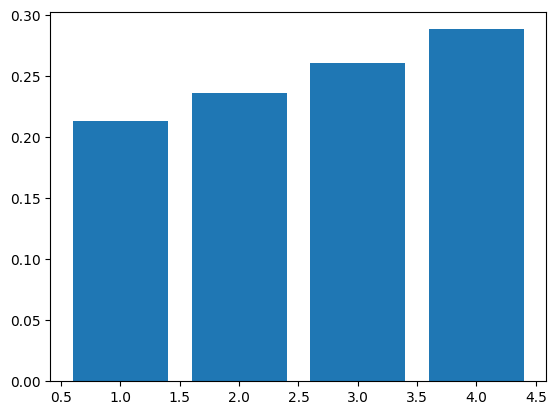

In [89]:
s1=torch.softmax(torch.tensor([-0.1, 0, 0.1, 0.2]), dim=-1)
print(s1)

plt.bar(x=range(1,len(s1)+1), height=s1.tolist())
plt.show()

tensor([0.0521, 0.1159, 0.2579, 0.5741])


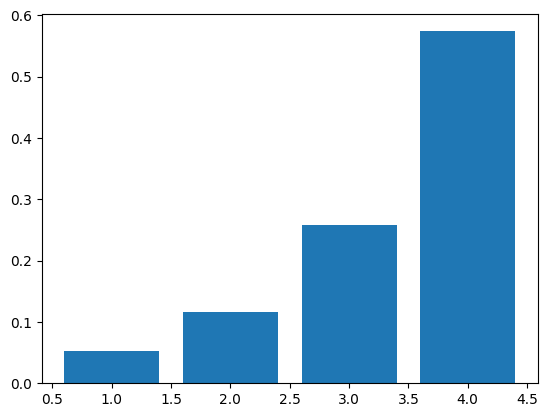

In [90]:
s2= torch.softmax(torch.tensor([-0.1, 0, 0.1, 0.2])*8, dim=-1)
print(s2)

plt.bar(x=range(1,len(s2)+1), height=s2.tolist())
plt.show()

Hence now we perform the Scaled Dot Product operation on our values.  

$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$

In [91]:
q= query(x)
k=key(x)
v=value(x)
# shape -> B,T,head_size

In [92]:
wei= F.softmax(q @ k.transpose(-2,-1) * head_size**(-0.5), dim=-1) @ v
wei.shape

torch.Size([4, 8, 16])

In [93]:
torch.manual_seed(2)

a= torch.randint(1,5, (3,3)).int()
print(a,end='\n\n')

b= torch.randint(1,5, (3,3)).int()
print(b)

tensor([[1, 4, 2],
        [1, 3, 4],
        [3, 4, 1]], dtype=torch.int32)

tensor([[4, 3, 2],
        [4, 4, 2],
        [4, 4, 4]], dtype=torch.int32)


In [94]:
bn= nn.BatchNorm1d(3)

In [95]:
y1 = bn(a.float())
print(y1)

tensor([[-0.7071,  0.7071, -0.2673],
        [-0.7071, -1.4142,  1.3363],
        [ 1.4142,  0.7071, -1.0690]], grad_fn=<NativeBatchNormBackward0>)


# Final Code

## Hyperparameters


In [96]:
batch_size= 64 # no. of sequences
block_size=16 # max context length
# seq_len=32 # context len
max_iters= 5001 # no. of iterations
embed_dim= 64 # numbers of dimensions a token is represented with
n_heads = 4 # no. of transformer heads (multi head attention)

head_size= embed_dim//n_heads # each head gets this amt of dimensions
n_blocks=4 # no. of transformer blocks

eval_interval = 50
learning_rate = 1e-3
eval_iters = 200
dropout_rate = 0.0

training_size= 0.9

## Data import

In [97]:
import os
import urllib.request

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

def get_data(path='input.txt'):

    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)

    with open(path, 'r', encoding='utf-8') as f:
        text = f.read()

    chars = sorted(set(text))
    vocab_size = len(chars)

    encoder_dic = {ch: i for i, ch in enumerate(chars)}
    decoder_dic = {i: ch for i, ch in enumerate(chars)}

    return text, chars, vocab_size, encoder_dic, decoder_dic

text, chars, vocab_size, encoder_dic, decoder_dic = get_data()

## Defining Encoder and Decoder functions

In [98]:
def encoder(text : str)-> list:
  encoded_text= []

  for ch in text:
    encoded_text.append(encoder_dic[ch])

  return encoded_text

print(encoder_example("Aaditya Gangurde"))

def decoder(text : list)-> str:
  decoded_text= ""

  for ch in text:
    decoded_text +=(decoder_dic[ch])

  return (decoded_text)

[13, 39, 42, 47, 58, 63, 39, 1, 19, 39, 52, 45, 59, 56, 42, 43]


## Splitting test and val data

In [99]:
data= torch.tensor(encoder(text), dtype=torch.long)

n= int(training_size*len(data))

train_data = data[:n]
val_data = data[n:]

## Get Batch

In [100]:
def get_batch(split : str):

  data= train_data if split== 'train' else val_data

  if len(data) <= block_size:
        raise ValueError("Dataset split must contain more tokens than block_size.")

  max_start_pos= len(data) - block_size

  # generates random starting point
  start_pos= torch.randint( # generates random no.
      low=0, # lower limit of range
      high=max_start_pos, # higher limit of range (exlusive)
      size=(batch_size,) # no. of random no. generated
  )

  input_seq = []
  target_seq = []

  for start in start_pos:
      input_seq.append(data[start:start + block_size])
      target_seq.append(data[start + 1:start + block_size + 1])

  input_batch = torch.stack(input_seq)
  target_batch = torch.stack(target_seq)

  return input_batch, target_batch

## Loss Estimate

In [101]:
@torch.no_grad()
def find_loss():

  avg_loss={} # dict of splits mapped to avg loss
  # looks like {'train':1.85, 'val':1.92}

  model.eval()

  for split in ['train','val']: # runs twice - split= train, split=val
    batch_losses= torch.zeros(eval_iters) # 1D tensor of 0s to calculate batch loss

    for i in range(eval_iters):
      x,y= get_batch(split) # x=input_batch, y=target_batch
      logits,loss= model(x,y) # get logits and loss through BLM model

      batch_losses[i]= loss.item()

    avg_loss[split]=batch_losses.mean()

  model.train()

  return avg_loss


## Defining Classes

### Attention Head Class

In [102]:
class AttentionHead(nn.Module):
    ''' Performs Attention on a single head '''

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(in_features=embed_dim,
                             out_features=head_size,
                             bias=False)
        self.query = nn.Linear(embed_dim, head_size, bias=False)
        self.value = nn.Linear(embed_dim, head_size, bias=False)

        # Lower triangle matrix used as mask
        # self.register_buffer() is a PyTorch method
        # Used to store a tensor inside a model without treating it as a learnable parameter.
        self.register_buffer(name='mask',
                             tensor=torch.tril(torch.ones(block_size, block_size)))

        # Randomly zeroes some attention weights
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, input_batch): # x is basically input_embeddings

        B,T,C = input_batch.shape
        # batch_size, seq_len, embed_dim

        keys= self.key(input_batch)
        queries = self.query(input_batch)
        values = self.value(input_batch)

        # Calculating attention scores and scaling them
        # Scale using the query/key dimension, not embed_dim
        attention_scores= (queries @ keys.transpose(-2,-1))*(queries.shape[-1]**-0.5)

        # create a mas
        mask= self.mask[:T,:T] # seq_len * seq_len

        # apply mask
        attention_scores= attention_scores.masked_fill(mask==0, float('-inf'))

        # apply softmax
        attention_weights = F.softmax(input=attention_scores, dim=-1)

        # applying dropouts to attention weights during training
        attention_weights = self.dropout(attention_weights)

        # Calculating output
        output= attention_weights @ values

        return output

### Multi Head Class


In [103]:
class MultiHeadAttention(nn.Module):
  '''
  Runs multiple heads parallely and combines their output
  NOTE- It does not implement attention calculation
  '''

  def __init__(self, n_heads, head_size):
    super().__init__()

    self.heads= nn.ModuleList( # ModuleList is a container that holds and registers multiple modules as children of parent
        [AttentionHead(head_size) for _ in range(n_heads)] # creates n_heads Head objects, each with different parameters
        )

    # Mixes the concatenated head outputs back together.
    # (num_heads * head_size) must equal embedding_dim for this shape to work.
    self.out_proj= nn.Linear(n_heads*head_size, embed_dim)

    # Randomly zeroes some values during training (regularization).
    self.dropout = nn.Dropout(dropout_rate)

  def forward(self, input_batch):

    # first we collect output from individual heads
    # we run every head on the same input
    head_outputs= [head(input_batch) for head in self.heads] # B,T,head_size

    output= torch.cat(head_outputs, # concatenated the outputs of heads
                      dim=-1) # B,T, head_size -> B,T,embed_dim

    output=self.dropout(self.out_proj(output))

    return output


### Feed Forward Class

In [104]:
class FeedFwd(nn.Module):
  """Processes each token's representation through a neural network."""

  def __init__(self, embed_dim):
    super().__init__()

    # Creating a Neural Network
    self.NeuralNetwork= nn.Sequential(
        # expand from embed_dim to 4*embed_dim (creating more features)
        nn.Linear(in_features=embed_dim, out_features=4*embed_dim),

        # introduces non linearity
        nn.ReLU(),

        # compress the features into original size
        nn.Linear(in_features=4*embed_dim, out_features=embed_dim),

        # randomly switch off some neurons
        nn.Dropout(dropout_rate)
    )

  def forward(self, input_batch):
    return self.NeuralNetwork(input_batch)

### Transformer Block Class

In [105]:
class TransformerBlock(nn.Module):
    """One Transformer block: communication (attention), then computation (feed-forward)."""

    def __init__(self, embed_dim, n_heads):

      super().__init__()
      head_size=embed_dim//n_heads

      self.attention= MultiHeadAttention(n_heads, head_size) # tokens talk to each other
      self.feed_forward= FeedFwd(embed_dim) # tokens think individually

      # LayerNorm before attention
      self.LN1= nn.LayerNorm(embed_dim)

      # LayerNorm before feed forward
      self.LN2= nn.LayerNorm(embed_dim)

      '''
      We used two different LayerNorm funcs because:
       - LN1 normalizes input to attention
       - LN2 normalizes attention to Feed Fwd
      Both have different parameters
      '''

    def forward(self, input_batch):

      # 1) Attention - First normalize then residual connection (out-of-place to preserve gradients)
      normalized= self.LN1(input_batch)
      attention_output= self.attention(normalized)
      input_batch = input_batch + attention_output

      # 2) FeedFwd (out-of-place to preserve gradients)
      normalized= self.LN2(input_batch)
      feedfwd_output= self.feed_forward(normalized)
      input_batch = input_batch + feedfwd_output

      return input_batch

### BLM Class

In [106]:
class BLM(nn.Module):

  def __init__(self):

        super().__init__()

        # Token embed
        # Input is token IDs with shape -> B,T
        # Output is -> B,T,C
        # Basically each token in the vocab is represented by embed_dim dimensional vector
        self.token_embed_table = nn.Embedding(vocab_size, embed_dim)

        # Position embeds
        # has size embed_dim
        self.position_token_embed_table = nn.Embedding(block_size, embed_dim)

        # Creates n_layer Transformer Blocks (objects)
        self.blocks= nn.Sequential(
            *[TransformerBlock(embed_dim, n_heads) # The * unpacks the list so nn.Sequential receives the blocks
            for _ in range(n_blocks)]
        )

        # FINAL LAYER NORMALIZATION
        # Normalizes the C features at each token position.
        self.LN_final= nn.LayerNorm(embed_dim)

        # LANGUAGE-MODEL HEAD
        # Converts each token's C features into vocab_size prediction scores.
        # Shape: (B, T, C) -> (B, T, vocab_size)
        self.LM_head= nn.Linear(embed_dim, vocab_size)


  def forward(self, input_batch, target_batch=None):

    B,T= input_batch.shape

    # B,T -> B,T,embed_dim
    token_embed= self.token_embed_table(input_batch)

    # basically a tensor that looks like [0,1,2...T-1]
    positions= torch.arange(
        start= 0, # default, inclusive
        end= T, # default , exclusive
        step=1 # default
    )

    position_embed = self.position_token_embed_table(positions)

    # Now we add the positional embedding and word embeddings to get the final embeddings
    embeddings= token_embed+position_embed

    # Now pass the these embeddings into all transformer blocks sequentially (objects of Blocks)
    embeddings= self.blocks(embeddings)

    # Final Normalization (LayerNorm)
    embeddings= self.LN_final(embeddings)

    # Calculating Logits
    # B,T,embed_dim -> B,T, vocab_size
    logits= self.LM_head(embeddings) # LM means Language Model

    if target_batch is None:
      loss= None
    else:
      batch_size, seq_len, vocab_size= logits.shape

      logits= logits.view(batch_size*seq_len, vocab_size) # reshaping
      # B,T,vocab_size -> B*T, vocab_size

      target_batch= target_batch.view(batch_size*seq_len) # reshaping
      # B,T -> B*T,

      loss= F.cross_entropy(logits, target_batch)

    return logits, loss


  def generate(self, input_batch, max_new_tokens):

    for i in range(max_new_tokens):

      # We don't want the entire sequence of a batch
      # Keep only last block_size elements
      context= input_batch[:, -block_size:]

      logits,loss= self(context) # no targets, so loss is None

      last_logits= logits[:,-1,:] # B,T,C -> B,C

      probs= F.softmax(last_logits, dim=-1) # Scores -> probabilities

      # Sample one next token per sequence.
      next_token= torch.multinomial(probs, num_samples=1)

      # Add the next token into the input_batch (not context)
      # (B, current_seq_len) + (B, 1) -> (B, current_seq_len + 1)
      input_batch=torch.cat((input_batch,next_token),
                            dim=1)

    return input_batch

## Main Function

In [107]:
model= BLM()
optimizer= torch.optim.AdamW(model.parameters(), lr=learning_rate)

iter_v_loss={}

for iter in range(max_iters):

  # Evaluate loss after every fixed intervals (like verbose)
  if iter % eval_interval == 0:
    losses= find_loss()
    print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
    iter_v_loss[iter]= losses

  input_batch, target_batch= get_batch('train')

  logits, loss= model(input_batch, target_batch)
  optimizer.zero_grad(set_to_none=True)
  loss.backward()
  optimizer.step()


context = torch.zeros((1, 1), dtype=torch.long)

model.eval()

with torch.no_grad():
    generated_tokens = model.generate(
        context,
        max_new_tokens=500
    )

generated_text = decoder(generated_tokens[0].tolist())
print(generated_text)

step 0: train loss 4.3964, val loss 4.4041
step 50: train loss 2.8699, val loss 2.8850
step 100: train loss 2.5570, val loss 2.5630
step 150: train loss 2.4230, val loss 2.4326
step 200: train loss 2.3447, val loss 2.3498
step 250: train loss 2.2655, val loss 2.2831
step 300: train loss 2.2165, val loss 2.2363
step 350: train loss 2.1622, val loss 2.1920
step 400: train loss 2.1238, val loss 2.1525
step 450: train loss 2.0883, val loss 2.1221
step 500: train loss 2.0654, val loss 2.1122
step 550: train loss 2.0341, val loss 2.0922
step 600: train loss 2.0081, val loss 2.0737
step 650: train loss 1.9878, val loss 2.0625
step 700: train loss 1.9772, val loss 2.0524
step 750: train loss 1.9509, val loss 2.0452
step 800: train loss 1.9262, val loss 2.0268
step 850: train loss 1.9159, val loss 2.0058
step 900: train loss 1.9059, val loss 2.0084
step 950: train loss 1.8765, val loss 1.9913
step 1000: train loss 1.8784, val loss 1.9932
step 1050: train loss 1.8687, val loss 1.9817
step 1100: 

In [108]:
model.train()

BLM(
  (token_embed_table): Embedding(65, 64)
  (position_token_embed_table): Embedding(16, 64)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x AttentionHead(
            (key): Linear(in_features=64, out_features=16, bias=False)
            (query): Linear(in_features=64, out_features=16, bias=False)
            (value): Linear(in_features=64, out_features=16, bias=False)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (out_proj): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (feed_forward): FeedFwd(
        (NeuralNetwork): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_features=64, bias=True)
          (3): Dropout(p=0.0, inplace=False)
        )
      )
      (LN1): LayerNorm((64,), eps=1e-05, e

In [109]:
# Extract iteration steps as a list
iters = list(iter_v_loss.keys())

# Extract only the actual numeric float values for training and validation
train_loss = [losses['train'] for losses in iter_v_loss.values()]
val_loss = [losses['val'] for losses in iter_v_loss.values()]

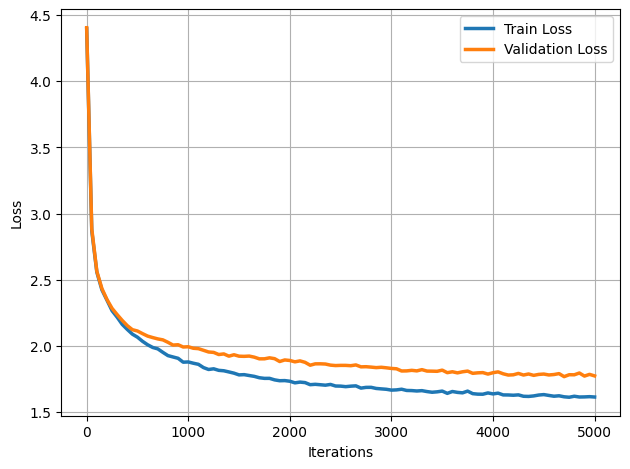

In [110]:
import matplotlib.pyplot as plt

plt.plot(iters, train_loss, label='Train Loss', linewidth=2.5)
plt.plot(iters, val_loss, label='Validation Loss', linewidth=2.5)
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## Training on GPT2

In [111]:
from transformers import GPT2LMHeadModel, GPT2Config
from torch.utils.data import DataLoader

In [112]:
torch.manual_seed(2)

In [113]:
config = GPT2Config(
    vocab_size=vocab_size,

    # Context and embedding dimensions
    n_positions=block_size,
    n_embd=embed_dim,

    # Transformer architecture
    n_layer=n_blocks,
    n_head=n_heads,

    # Regularization
    resid_pdrop=dropout_rate,
    embd_pdrop=dropout_rate,
    attn_pdrop=dropout_rate,

    # Special token IDs (unused for this character-level setup)
    bos_token_id=0,
    eos_token_id=0,
)

In [114]:
gpt_model= GPT2LMHeadModel(config=config)

In [115]:
print("No. of param: ",sum(p.numel() for p in gpt_model.parameters()))

No. of param:  205248


In [116]:
optimizer= torch.optim.AdamW(
    gpt_model.parameters(),
    lr=learning_rate
)

In [117]:
def get_batch_gpt(split):
    data = train_data if split == 'train' else val_data

    if len(data) <= block_size:
        raise ValueError("Dataset split must contain more tokens than block_size.")

    max_start_pos = len(data) - block_size
    start_pos = torch.randint(
        low=0,
        high=max_start_pos,
        size=(batch_size,)
    )

    input_seq = []
    target_seq = []

    for start in start_pos:
        start = int(start)
        input_seq.append(data[start : start + block_size])
        target_seq.append(data[start + 1 : start + block_size + 1])

    input_batch = torch.stack(input_seq)
    target_batch = torch.stack(target_seq)

    return input_batch, target_batch

In [118]:
@torch.no_grad()
def estimate_loss_gpt():
    gpt_model.eval()
    results = {}

    for split in ['train', 'val']:
        batch_losses = []

        for _ in range(eval_iters):
            input_batch, target_batch = get_batch_gpt(split)

            model_output = gpt_model(
                input_ids=input_batch,
                labels=input_batch
            )
            batch_losses.append(model_output.loss.item())

        results[split] = sum(batch_losses) / len(batch_losses)

    gpt_model.train()
    return results

In [119]:
gpt_model.train()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(65, 64)
    (wpe): Embedding(16, 64)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-3): 4 x GPT2Block(
        (ln_1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=192, nx=64)
          (c_proj): Conv1D(nf=64, nx=64)
          (attn_dropout): Dropout(p=0.0, inplace=False)
          (resid_dropout): Dropout(p=0.0, inplace=False)
        )
        (ln_2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=256, nx=64)
          (c_proj): Conv1D(nf=64, nx=256)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=64, out_features=65, bias=False)
)

In [120]:
iter_v_gpt_loss={}

for step in range(max_iters):

    if step % eval_interval == 0:
        losses = estimate_loss_gpt()
        iter_v_gpt_loss[step] = losses

        print(
            f"Step {step:4d} | "
            f"Train loss: {losses['train']:.4f} | "
            f"Val loss: {losses['val']:.4f}"
        )

    input_batch, target_batch = get_batch_gpt('train')

    model_output = gpt_model(
        input_ids=input_batch,
        labels=input_batch
    )
    loss = model_output.loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

losses = estimate_loss_gpt()

print("\nFinal results:")
print(f"Train loss: {losses['train']:.4f}")
print(f"Val loss:   {losses['val']:.4f}")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step    0 | Train loss: 4.1980 | Val loss: 4.1961
Step   50 | Train loss: 2.8289 | Val loss: 2.8399
Step  100 | Train loss: 2.5805 | Val loss: 2.5850
Step  150 | Train loss: 2.4685 | Val loss: 2.4669
Step  200 | Train loss: 2.4181 | Val loss: 2.4187
Step  250 | Train loss: 2.3635 | Val loss: 2.3662
Step  300 | Train loss: 2.3144 | Val loss: 2.3076
Step  350 | Train loss: 2.2811 | Val loss: 2.2839
Step  400 | Train loss: 2.2236 | Val loss: 2.2316
Step  450 | Train loss: 2.2070 | Val loss: 2.2224
Step  500 | Train loss: 2.1746 | Val loss: 2.1923
Step  550 | Train loss: 2.1483 | Val loss: 2.1704
Step  600 | Train loss: 2.1334 | Val loss: 2.1556
Step  650 | Train loss: 2.1004 | Val loss: 2.1468
Step  700 | Train loss: 2.0862 | Val loss: 2.1291
Step  750 | Train loss: 2.0731 | Val loss: 2.1197
Step  800 | Train loss: 2.0476 | Val loss: 2.1029
Step  850 | Train loss: 2.0413 | Val loss: 2.0844
Step  900 | Train loss: 2.0312 | Val loss: 2.0712
Step  950 | Train loss: 2.0129 | Val loss: 2.0633


## Comparison

In [121]:
train_loss_gpt = [losses['train'] for losses in iter_v_gpt_loss.values()]
val_loss_gpt = [losses['val'] for losses in iter_v_gpt_loss.values()]

In [122]:
iters = list(iter_v_gpt_loss.keys())

train_loss_gpt = [losses['train'] for losses in iter_v_gpt_loss.values()]
val_loss_gpt = [losses['val'] for losses in iter_v_gpt_loss.values()]

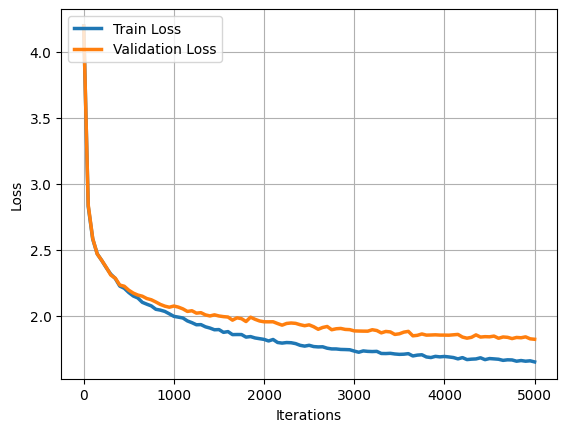

In [123]:
plt.plot(iters, train_loss_gpt, label='Train Loss', linewidth=2.5)
plt.plot(iters, val_loss_gpt, label='Validation Loss', linewidth=2.5)
plt.grid()
plt.legend(loc='upper left')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.tight_layout
plt.show()

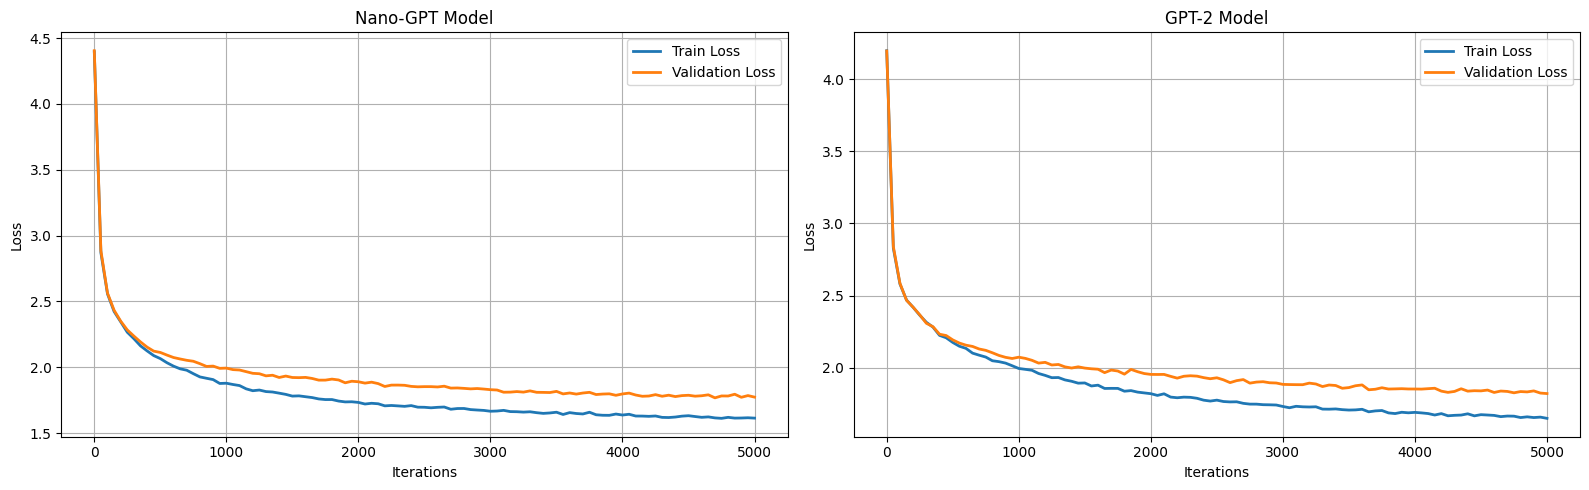

In [124]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot custom BLM Transformer losses
ax1.plot(iters, train_loss, label='Train Loss', linewidth=2)
ax1.plot(iters, val_loss, label='Validation Loss', linewidth=2)
ax1.set_title('Nano-GPT Model')
ax1.set_xlabel('Iterations')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Plot GPT-2 losses
ax2.plot(iters, train_loss_gpt, label='Train Loss', linewidth=2)
ax2.plot(iters, val_loss_gpt, label='Validation Loss', linewidth=2)
ax2.set_title('GPT-2 Model')
ax2.set_xlabel('Iterations')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

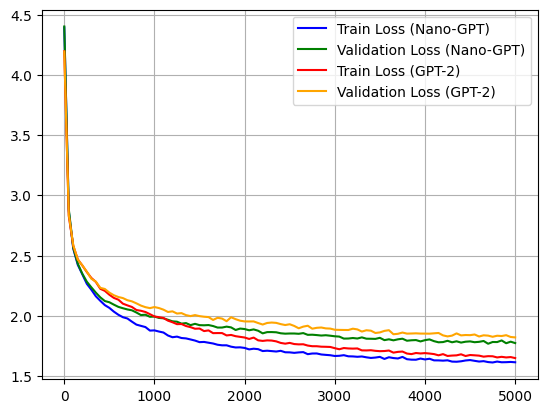

In [125]:
plt.plot(iters, train_loss, label='Train Loss (Nano-GPT)', color='blue', linewidth=1.5)
plt.plot(iters, val_loss, label='Validation Loss (Nano-GPT)', color='green', linewidth=1.5)
plt.plot(iters, train_loss_gpt, label='Train Loss (GPT-2)', color='red', linewidth=1.5)
plt.plot(iters, val_loss_gpt, label='Validation Loss (GPT-2)', color='orange', linewidth=1.5)
plt.legend()
plt.grid()